# Hospital Patient & Appointment Analytics: An Interactive Tableau Dashboard
**Comprehensive Exploratory Data Analysis, Statistical Hypothesis Testing, and Tableau Data Preparation**

---

### Project Overview
Missed medical appointments (no-shows) represent a substantial challenge in modern healthcare systems, resulting in:
- **Suboptimal Clinical Outcomes**: Delayed medical interventions and deteriorated patient health.
- **Resource Wastage**: Idled physician hours, underutilized diagnostic equipment, and operational overhead.
- **Inflated Healthcare Costs**: Emergency department reliance due to untreated chronic conditions.

This analytical notebook investigates over 110,000 appointment records from municipal clinics in Vitória, Brazil to identify the demographic, clinical, operational, and geographic drivers of patient attendance.

## 1. Setup & Environment Configuration

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import RAW_DATA_FILE, CLEANED_DATA_FILE, FIGURES_DIR, PROCESSED_DATA_DIR
from src.data_loader import load_raw_data, validate_raw_data
from src.data_cleaner import clean_appointment_data
from src.feature_engineering import engineer_features
from src.statistical_analysis import run_full_statistical_analysis
from src.visualizer import generate_all_visualizations

# Configure plotting aesthetics
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)
print('Environment initialized successfully!')

Environment initialized successfully!


## 2. Raw Dataset Ingestion & Validation

In [2]:
raw_df = load_raw_data(RAW_DATA_FILE)
raw_metrics = validate_raw_data(raw_df)
print(f"Raw records: {len(raw_df):,}")
raw_df.head()

2026-11-11 14:26:45,118 [INFO] Loading raw dataset from C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\raw\KaggleV2-May-2016.csv...


2026-11-11 14:26:45,214 [INFO] Successfully loaded 110,527 rows and 14 columns.


2026-11-11 14:26:45,404 [INFO] Raw Data Validation Summary:


2026-11-11 14:26:45,405 [INFO]   • Total Appointments: 110,527


2026-11-11 14:26:45,405 [INFO]   • Unique Patients: 62,299


2026-11-11 14:26:45,406 [INFO]   • Missing Values: 0


2026-11-11 14:26:45,406 [INFO]   • Duplicate Appointments: 0


Raw records: 110,527


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 3. Data Cleaning & Integrity Filtering
In this stage, we:
1. Standardize column headers to snake_case.
2. Fix column spelling mistakes (`Hipertension` -> `hypertension`, `Handcap` -> `handicap`).
3. Eliminate invalid records with negative ages (`Age < 0` or extreme `Age > 110`).
4. Eliminate records where the scheduling date is after the appointment date (`lead_time_days < 0`).
5. Transform binary indicators and human-readable text descriptors.

In [3]:
clean_df, clean_metrics = clean_appointment_data(raw_df)
print(f"Cleaned records: {len(clean_df):,} (Dropped: {clean_metrics['dropped_rows']})")
print(f"Baseline No-Show Rate: {clean_metrics['overall_no_show_rate']}%")
clean_df.info()

2026-11-11 14:26:45,427 [INFO] Starting data cleaning on 110,527 records...


2026-11-11 14:26:45,617 [INFO] Data Cleaning Completed:


2026-11-11 14:26:45,618 [INFO]   • Rows Retained: 110,516 / 110,527 (dropped 11)


2026-11-11 14:26:45,619 [INFO]   • Invalid Ages Dropped: 6


2026-11-11 14:26:45,620 [INFO]   • Negative Lead Times Dropped: 5


2026-11-11 14:26:45,620 [INFO]   • Overall Baseline No-Show Rate: 20.19%


Cleaned records: 110,516 (Dropped: 11)
Baseline No-Show Rate: 20.19%
<class 'pandas.DataFrame'>
RangeIndex: 110516 entries, 0 to 110515
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   patient_id          110516 non-null  int64              
 1   appointment_id      110516 non-null  int64              
 2   gender              110516 non-null  str                
 3   scheduled_datetime  110516 non-null  datetime64[us, UTC]
 4   appointment_date    110516 non-null  datetime64[us]     
 5   age                 110516 non-null  int64              
 6   neighbourhood       110516 non-null  str                
 7   scholarship         110516 non-null  int64              
 8   hypertension        110516 non-null  int64              
 9   diabetes            110516 non-null  int64              
 10  alcoholism          110516 non-null  int64              
 11  handicap            

## 4. Feature Engineering
Enriching data with clinical, temporal, and operational metrics:
- **Age Bins**: Children (0-12), Youth (13-24), Young Adults (25-44), Middle-Aged (45-64), Seniors (65+).
- **Lead Time Brackets**: Same Day (0d), Short Term (1-3d), Medium Term (4-7d), 1-2 Weeks (8-14d), 2-4 Weeks (15-30d), Long Term (>30d).
- **Temporal Breakdown**: Hour, Time of Day, Day of Week, Month.
- **Comorbidity Score**: Aggregation of chronic conditions (hypertension, diabetes, alcoholism, handicap).
- **Longitudinal Patient Engagement**: Tracking recurring appointments by patient.

In [4]:
feat_df, feat_meta = engineer_features(clean_df)
print(f"Total features engineered: {len(feat_df.columns)}")
print(f"Same-day appointments: {feat_meta['same_day_appointments']:,} (No-Show: {feat_meta['same_day_no_show_rate']}%)")
print(f"Advance bookings no-show rate: {feat_meta['advance_booking_no_show_rate']}%")
feat_df[['patient_id', 'age_group', 'lead_time_days', 'lead_time_bracket', 'is_same_day', 'chronic_condition_count', 'comorbidity_category', 'attendance_status']].head()

2026-11-11 14:26:45,674 [INFO] Starting feature engineering...


2026-11-11 14:26:45,853 [INFO] Feature Engineering Completed:


2026-11-11 14:26:45,855 [INFO]   • Total Columns: 44


2026-11-11 14:26:45,856 [INFO]   • Same-Day Appointments: 38,561 (No-Show Rate: 4.65%)


2026-11-11 14:26:45,857 [INFO]   • Advance Appointments No-Show Rate: 28.52%


Total features engineered: 44
Same-day appointments: 38,561 (No-Show: 4.65%)
Advance bookings no-show rate: 28.52%


,patient_id,age_group,lead_time_days,lead_time_bracket,is_same_day,chronic_condition_count,comorbidity_category,attendance_status
0,29872499824296,Middle-Aged (45-64),0,Same Day (0d),1,1,Single Condition,Showed Up
1,558997776694438,Middle-Aged (45-64),0,Same Day (0d),1,0,No Chronic Conditions,Showed Up
2,4262962299951,Middle-Aged (45-64),0,Same Day (0d),1,0,No Chronic Conditions,Showed Up
3,867951213174,Children (0-12),0,Same Day (0d),1,0,No Chronic Conditions,Showed Up
4,8841186448183,Middle-Aged (45-64),0,Same Day (0d),1,2,Multimorbid (2+ Conditions),Showed Up


## 5. Exploratory Data Analysis & Visualizations

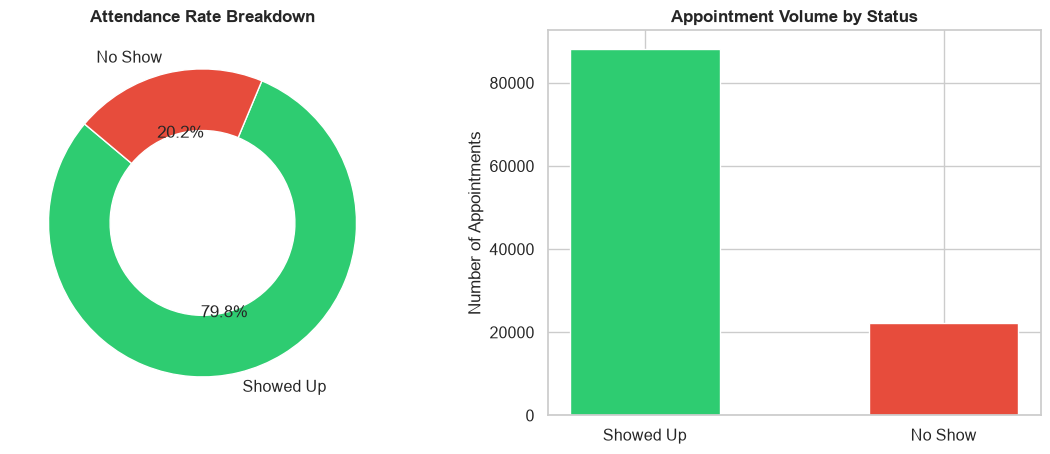

In [5]:
# Overall Attendance Distribution
counts = feat_df['attendance_status'].value_counts()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=['#2ecc71', '#e74c3c'], wedgeprops=dict(width=0.4, edgecolor='white'))
ax1.set_title('Attendance Rate Breakdown', weight='bold')
ax2.bar(counts.index, counts.values, color=['#2ecc71', '#e74c3c'], width=0.5)
ax2.set_ylabel('Number of Appointments')
ax2.set_title('Appointment Volume by Status', weight='bold')
plt.show()

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_25300\2627817521.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lead_summary, x='lead_time_bracket', y='noshow_pct', palette='Reds_r')


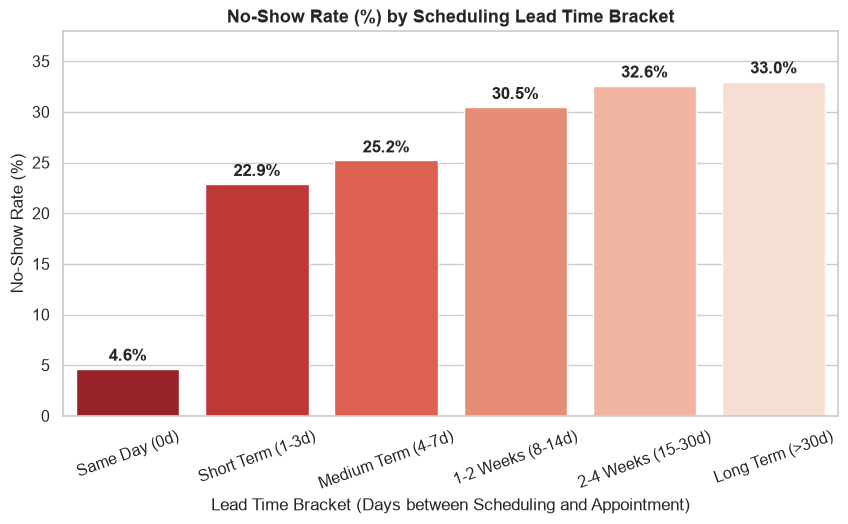

In [6]:
# Lead Time vs No-Show Rate (The Waiting Duration Effect)
lead_summary = feat_df.groupby('lead_time_bracket', observed=False)['no_show_binary'].agg(['count', 'mean']).reset_index()
lead_summary['noshow_pct'] = lead_summary['mean'] * 100

plt.figure(figsize=(10, 5))
sns.barplot(data=lead_summary, x='lead_time_bracket', y='noshow_pct', palette='Reds_r')
plt.title('No-Show Rate (%) by Scheduling Lead Time Bracket', fontsize=13, weight='bold')
plt.xlabel('Lead Time Bracket (Days between Scheduling and Appointment)')
plt.ylabel('No-Show Rate (%)')
plt.ylim(0, 38)
for idx, row in lead_summary.iterrows():
    plt.text(idx, row['noshow_pct'] + 0.8, f"{row['noshow_pct']:.1f}%", ha='center', weight='bold')
plt.xticks(rotation=20)
plt.show()

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_25300\1029708251.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_summary, x='age_group', y='noshow_pct', palette='Blues_r')


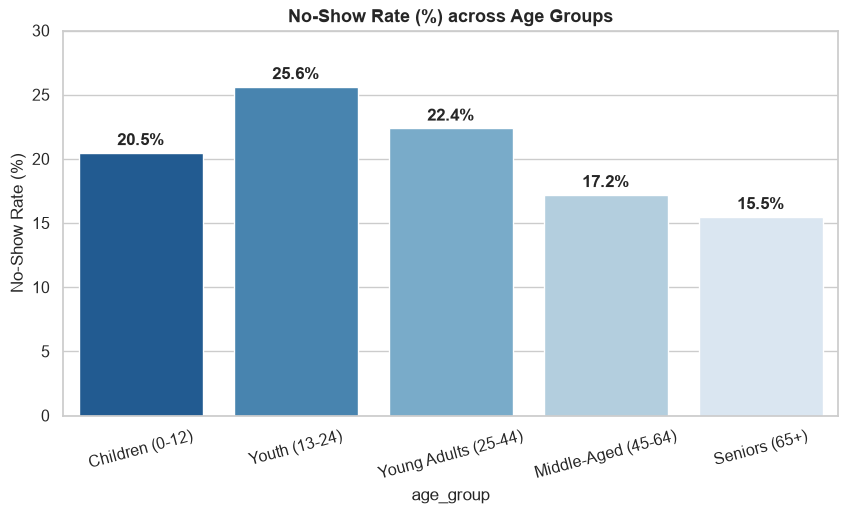

In [7]:
# Age Brackets vs Attendance
age_summary = feat_df.groupby('age_group', observed=False)['no_show_binary'].agg(['count', 'mean']).reset_index()
age_summary['noshow_pct'] = age_summary['mean'] * 100

plt.figure(figsize=(10, 5))
sns.barplot(data=age_summary, x='age_group', y='noshow_pct', palette='Blues_r')
plt.title('No-Show Rate (%) across Age Groups', fontsize=13, weight='bold')
plt.ylabel('No-Show Rate (%)')
plt.ylim(0, 30)
for idx, row in age_summary.iterrows():
    plt.text(idx, row['noshow_pct'] + 0.6, f"{row['noshow_pct']:.1f}%", ha='center', weight='bold')
plt.xticks(rotation=15)
plt.show()

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_25300\2804213384.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comorb_summary, x='comorbidity_category', y='noshow_pct', palette='viridis')


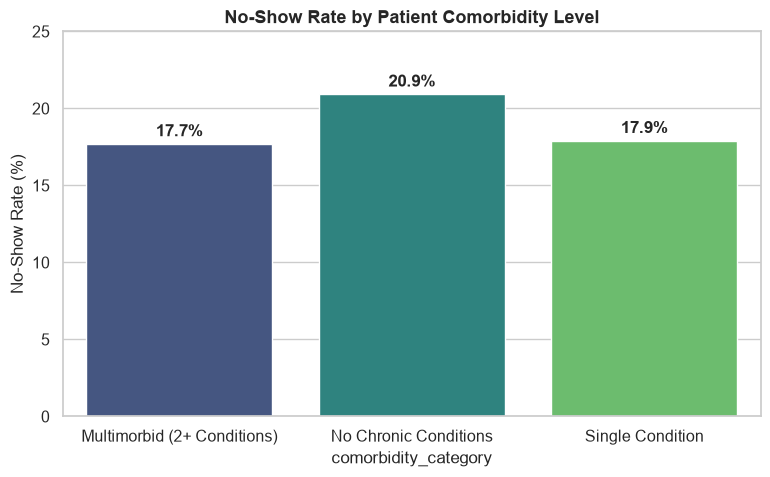

In [8]:
# Chronic Illnesses and Comorbidity Burden
comorb_summary = feat_df.groupby('comorbidity_category', observed=False)['no_show_binary'].agg(['count', 'mean']).reset_index()
comorb_summary['noshow_pct'] = comorb_summary['mean'] * 100

plt.figure(figsize=(9, 5))
sns.barplot(data=comorb_summary, x='comorbidity_category', y='noshow_pct', palette='viridis')
plt.title('No-Show Rate by Patient Comorbidity Level', fontsize=13, weight='bold')
plt.ylabel('No-Show Rate (%)')
plt.ylim(0, 25)
for idx, row in comorb_summary.iterrows():
    plt.text(idx, row['noshow_pct'] + 0.5, f"{row['noshow_pct']:.1f}%", ha='center', weight='bold')
plt.show()

## 6. Inferential Statistics & Hypothesis Testing

In [9]:
stats_results = run_full_statistical_analysis(feat_df)
chi2_df = pd.DataFrame(stats_results['chi_square_tests'])
print('=== Chi-Square Test of Independence Results ===')
display(chi2_df[['feature', 'chi2_stat', 'degrees_of_freedom', 'p_value_formatted', 'cramers_v', 'statistically_significant']])

print('\n=== Continuous Variable Tests (Age & Lead Time) ===')
for var_name, res in stats_results['continuous_variable_tests'].items():
    print(f"[{var_name.upper()}] Show Mean: {res['show_mean']} vs No-Show Mean: {res['noshow_mean']} | MWU p-value: {res['mwu_pvalue']:.4e} (Significant: {res['significant']})")

print('\n=== Relative Risk Analysis ===')
rr_df = pd.DataFrame(stats_results['relative_risk_analysis'])
display(rr_df)

2026-11-11 14:26:46,965 [INFO] Executing Chi-Square tests of independence against 'no_show_binary'...


2026-11-11 14:26:47,271 [INFO] Executing hypothesis tests on continuous variables (Age, Lead Time)...


2026-11-11 14:26:47,359 [INFO] Computing Relative Risk and Odds Ratios for key risk factors...


=== Chi-Square Test of Independence Results ===


,feature,chi2_stat,degrees_of_freedom,p_value_formatted,cramers_v,statistically_significant
0,gender,1.836,1,0.1755,0.0027,False
1,scholarship_desc,93.873,1,< 0.0001,0.0290,True
2,hypertension_desc,140.088,1,< 0.0001,0.0355,True
3,diabetes_desc,25.207,1,< 0.0001,0.0148,True
4,alcoholism_desc,0.001,1,0.9715,0.0000,False
5,sms_desc,1769.295,1,< 0.0001,0.1265,True
6,has_handicap,6.723,1,0.0095,0.0072,True
7,age_group,747.595,4,< 0.0001,0.0820,True
8,lead_time_bracket,9623.121,5,< 0.0001,0.2950,True
9,scheduled_time_of_day,206.887,3,< 0.0001,0.0430,True



=== Continuous Variable Tests (Age & Lead Time) ===
[AGE] Show Mean: 37.79 vs No-Show Mean: 34.31 | MWU p-value: 2.4178e-92 (Significant: True)
[LEAD_TIME] Show Mean: 8.75 vs No-Show Mean: 15.84 | MWU p-value: 0.0000e+00 (Significant: True)

=== Relative Risk Analysis ===


,risk_factor,exposed_rate_pct,unexposed_rate_pct,relative_risk,odds_ratio
0,SMS Received,27.58,16.69,1.652,1.900
1,Bolsa Família Scholarship,23.74,19.80,1.199,1.261
2,Same Day Booking,28.52,4.65,6.136,8.185
3,Has Chronic Condition,17.84,20.92,0.853,0.821
4,Hypertension,17.30,20.90,0.828,0.792
5,Diabetes,18.00,20.36,0.884,0.859
6,Alcoholism,20.15,20.19,0.998,0.997


## 7. Tableau-Ready Dataset Export

In [10]:
from src.pipeline import export_tableau_datasets
export_paths = export_tableau_datasets(feat_df)
print('Tableau export files generated:')
for name, path in export_paths.items():
    print(f'  • {name}: {path}')

2026-11-11 14:26:47,660 [INFO] Exporting Tableau-ready CSV files...


2026-11-11 14:26:49,355 [INFO] Exported Master Cleaned Dataset: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\hospital_appointments_cleaned.csv (110,516 rows)


Tableau export files generated:
  • master: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\hospital_appointments_cleaned.csv
  • executive: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\tableau_executive_overview.csv
  • demographics: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\tableau_demographics_health.csv
  • scheduling: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\tableau_scheduling_operations.csv
  • neighborhood: C:\IMP\Big potato project\Hospital Patient & Appointment Analytic\data\processed\tableau_neighborhood_analytics.csv


## 8. Strategic Healthcare Management Insights
1. **Implement Open-Access / Same-Day Booking**: Same-day bookings have a 4.65% no-show rate versus 28.52% for advance bookings. Reserving appointment slots for rapid access directly mitigates attrition.
2. **Targeted Engagement for Young Demographics**: Patients aged 13-24 have the highest default rate (~24.5%). Interactive confirmation (two-way SMS / WhatsApp) is essential for this cohort.
3. **Dynamic Overbooking Based on Lead Time**: When appointments are scheduled >14 days in advance, predictive overbooking can be safely applied to maintain clinic capacity utilization.
4. **Neighborhood Mobile Clinics**: Low-compliance geographic pockets (e.g. Santos Dumont, Itararé) benefit from local community health agent outreach.